In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load cleaned dataset
DATA_PATH = "../data/processed/cleaned_fraud_data.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFraud Distribution:")
print(df["isFraud"].value_counts())

Dataset Shape: (6362620, 11)

Columns:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Data Types:
step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

Missing Values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Fraud Distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [2]:
# Fraud vs Non-Fraud Distribution

fraud_counts = df["isFraud"].value_counts()

print("Non-Fraud (0):", fraud_counts[0])
print("Fraud (1):", fraud_counts[1])

print("\nFraud Percentage:")
print(df["isFraud"].value_counts(normalize=True) * 100)

Non-Fraud (0): 6354407
Fraud (1): 8213

Fraud Percentage:
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


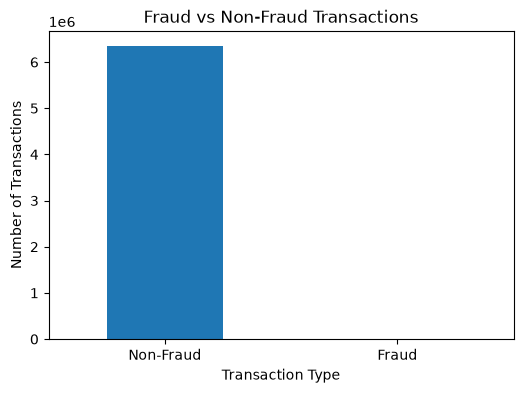

In [3]:
# visualize fraud detection 
# Fraud Distribution Plot

plt.figure(figsize=(6, 4))

df["isFraud"].value_counts().plot(kind="bar")

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Non-Fraud", "Fraud"], rotation=0)

plt.show()

Transaction Types:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


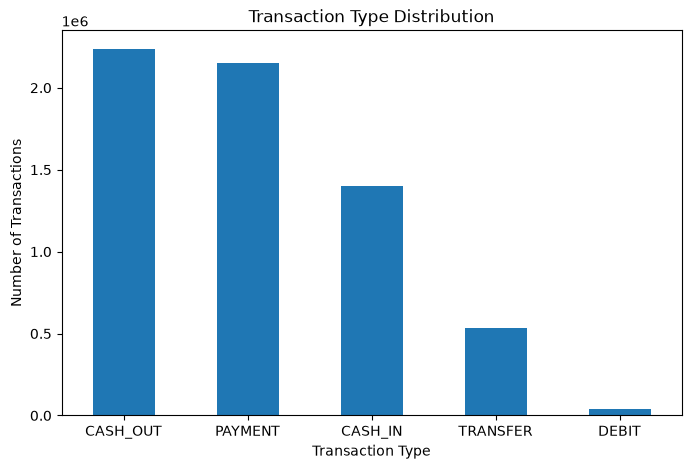

In [4]:
# transaction type of analysis
# Transaction Type Distribution

print("Transaction Types:")
print(df["type"].value_counts())

plt.figure(figsize=(8, 5))

df["type"].value_counts().plot(kind="bar")

plt.title("Transaction Type Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.show()

isFraud         0     1
type                   
CASH_IN   1399284     0
CASH_OUT  2233384  4116
DEBIT       41432     0
PAYMENT   2151495     0
TRANSFER   528812  4097


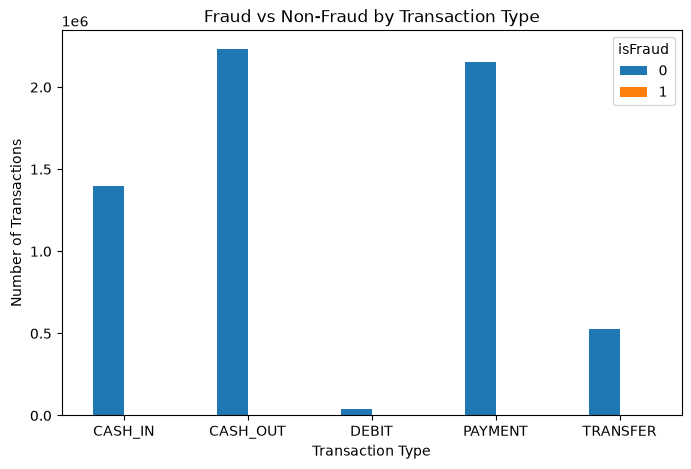

In [5]:
# fraud by transaction type
# Fraud by Transaction Type

fraud_by_type = pd.crosstab(df["type"], df["isFraud"])

print(fraud_by_type)

fraud_by_type.plot(kind="bar", figsize=(8, 5))

plt.title("Fraud vs Non-Fraud by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.show()

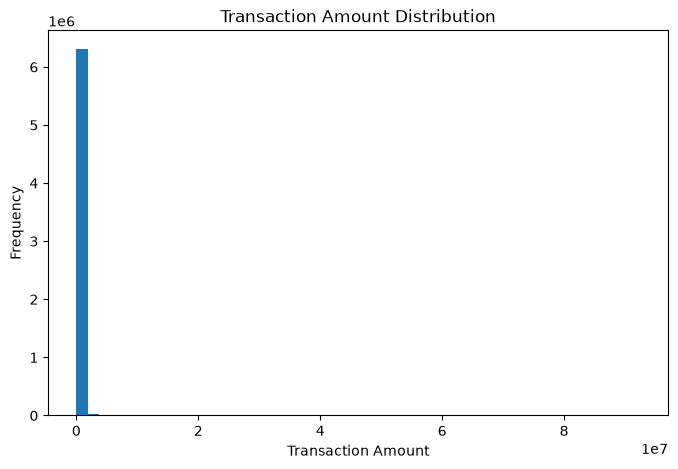

In [6]:
# transaction amount analysis
# Transaction Amount Distribution

plt.figure(figsize=(8, 5))

plt.hist(df["amount"], bins=50)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

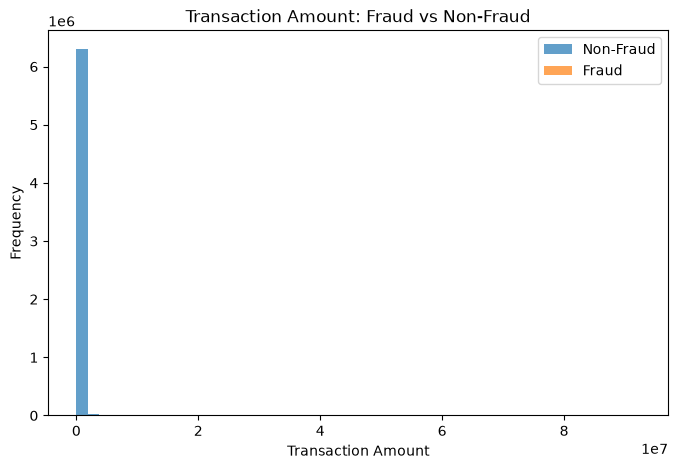

In [7]:
# fraud amounta analysis
# Transaction Amount: Fraud vs Non-Fraud

plt.figure(figsize=(8, 5))

plt.hist(
    df[df["isFraud"] == 0]["amount"],
    bins=50,
    alpha=0.7,
    label="Non-Fraud"
)

plt.hist(
    df[df["isFraud"] == 1]["amount"],
    bins=50,
    alpha=0.7,
    label="Fraud"
)

plt.title("Transaction Amount: Fraud vs Non-Fraud")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.legend()

plt.show()

Fraud Rate by Transaction Type:
type
CASH_IN     0.000000
CASH_OUT    0.183955
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.768799
Name: isFraud, dtype: float64


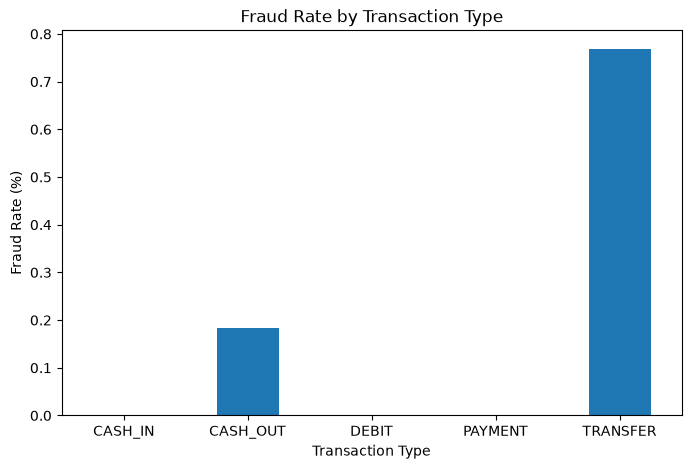

In [8]:
# fraud rate by transaction type 
# Fraud Rate by Transaction Type

fraud_rate_by_type = df.groupby("type")["isFraud"].mean() * 100

print("Fraud Rate by Transaction Type:")
print(fraud_rate_by_type)

plt.figure(figsize=(8, 5))

fraud_rate_by_type.plot(kind="bar")

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [9]:
# numerical feature correlation analysis
# Correlation with Fraud Target

numeric_columns = df.select_dtypes(include=["int64", "float64"]).columns

correlation = df[numeric_columns].corr()["isFraud"].sort_values(ascending=False)

print("Correlation with isFraud:")
print(correlation)

Correlation with isFraud:
isFraud           1.000000
amount            0.076688
isFlaggedFraud    0.044109
step              0.031578
oldbalanceOrg     0.010154
newbalanceDest    0.000535
oldbalanceDest   -0.005885
newbalanceOrig   -0.008148
Name: isFraud, dtype: float64


In [10]:
# Fraud Percentage by Transaction Type

fraud_percentage = pd.crosstab(
    df["type"],
    df["isFraud"],
    normalize="index"
) * 100

fraud_percentage.columns = ["Non-Fraud (%)", "Fraud (%)"]

print(fraud_percentage)


          Non-Fraud (%)  Fraud (%)
type                              
CASH_IN      100.000000   0.000000
CASH_OUT      99.816045   0.183955
DEBIT        100.000000   0.000000
PAYMENT      100.000000   0.000000
TRANSFER      99.231201   0.768799


In [11]:
# Summary Statistics

print("Summary Statistics:")
display(df.describe())

Summary Statistics:


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [12]:
# Numerical Columns

numeric_columns = df.select_dtypes(include=["int64", "float64"]).columns

print("Numerical Columns:")
print(numeric_columns.tolist())

Numerical Columns:
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [13]:
# Categorical Columns

categorical_columns = df.select_dtypes(include=["object", "str"]).columns

print("Categorical Columns:")
print(categorical_columns.tolist())

Categorical Columns:
['type', 'nameOrig', 'nameDest']


In [14]:
# Number of Fraud Transactions by Type

fraud_transactions = df[df["isFraud"] == 1]

print("Fraud Transactions by Type:")
print(fraud_transactions["type"].value_counts())

Fraud Transactions by Type:
type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64
